# Euler explícito: arranque de un motor de CD

**Objetivo:** simular el modelo desde varias condiciones iniciales e interpretar
su evolución temporal y su retrato de fase.

Sin par de carga y con voltaje constante, los estados satisfacen
$\dot i_a=(V_a-R_ai_a-K_e\omega)/L_a$ y
$\dot\omega=(K_ti_a-B\omega)/J$. Se aplica $V_a=12$ V; la trayectoria
principal parte del reposo y de corriente cero.

El método usa $x_{k+1}=x_k+h f(t_k,x_k)$. La biblioteca del curso implementa
esta actualización; la elección de paso debe verificarse frente a una solución
de referencia, porque una gráfica por sí sola no demuestra exactitud.

In [1]:
%matplotlib inline
import numpy as np
from sistemas_dinamicos import integrar, graficar, retrato_fase

Va, Ra, La, Kt, Ke, J, B = 12.0, 1.2, 0.05, 0.08, 0.08, 0.002, 0.001
def f(t, x):
    i, w = x
    return np.array([(Va-Ra*i-Ke*w)/La, (Kt*i-B*w)/J])
equilibrio = (B*Va/(Ra*B+Kt*Ke), Kt*Va/(Ra*B+Kt*Ke))
print("Equilibrio (A, rad/s):", equilibrio)
h = 0.0005
t = np.linspace(0, 2.0, round(2.0/h) + 1)
condiciones = [[0, 0], [10, 0], [0, 175], [10, 175], [-2, 80], [6, 160]]
trayectorias = [integrar(f, t, x0, metodo="euler") for x0 in condiciones]
principal = trayectorias[0]
print("Paso:", t[1]-t[0], "s; condición inicial:", condiciones[0])

Equilibrio (A, rad/s): (1.5789473684210527, 126.3157894736842)
Paso: 0.0005 s; condición inicial: [0, 0]


## Evolución temporal

La primera condición inicial es la trayectoria principal.

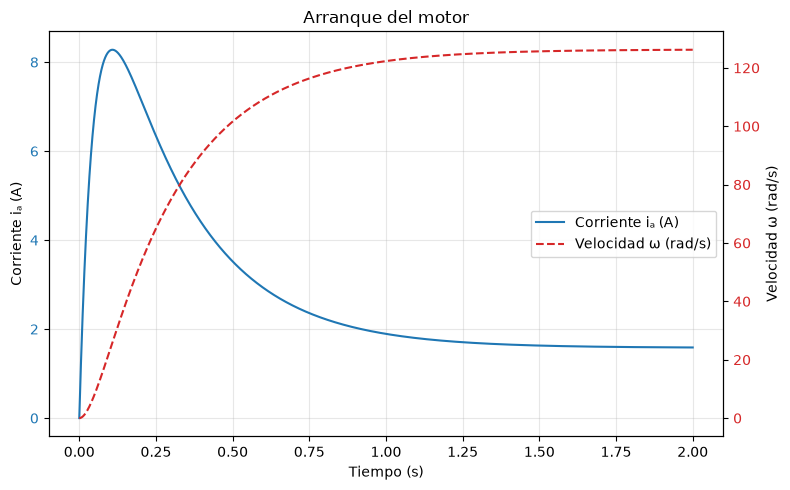

In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t, principal[:, 0], color="tab:blue", label="Corriente iₐ (A)")
ax.set(xlabel="Tiempo (s)", ylabel="Corriente iₐ (A)", title="Arranque del motor")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.grid(True, alpha=0.3)
ax2 = ax.twinx()
ax2.plot(t, principal[:, 1], color="tab:red", linestyle="--", label="Velocidad ω (rad/s)")
ax2.set_ylabel("Velocidad ω (rad/s)")
ax2.tick_params(axis="y", labelcolor="tab:red")
lineas = ax.get_lines() + ax2.get_lines()
ax.legend(lineas, [linea.get_label() for linea in lineas], loc="center right")
fig.tight_layout();

## Retrato de fase

Cada punto negro marca el inicio de una trayectoria.

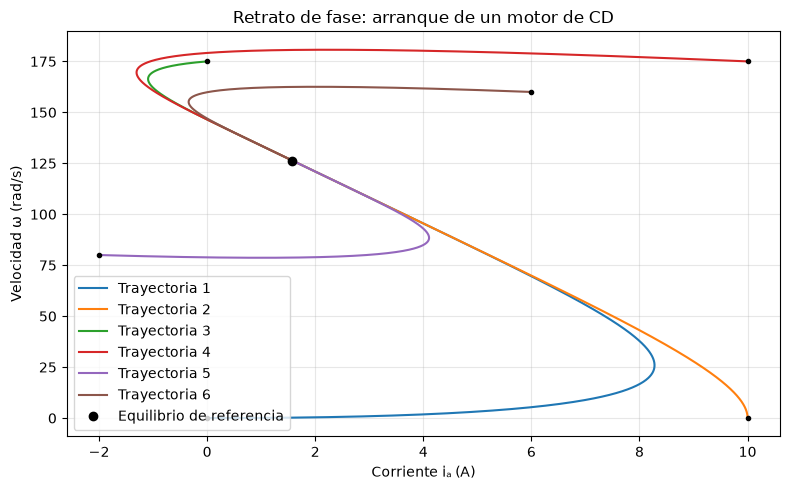

In [3]:
fig, ax = retrato_fase(trayectorias, titulo="Retrato de fase: arranque de un motor de CD",
                        xlabel="Corriente iₐ (A)", ylabel="Velocidad ω (rad/s)")
ax.plot(*equilibrio, "ko", label="Equilibrio de referencia")
ax.legend();

## Interpretación y práctica

Las trayectorias se aproximan al punto de operación de aproximadamente
$1.58$ A y $126.32$ rad/s. Corriente y velocidad tienen distintas unidades y
escalas, así que se muestran en ejes verticales separados.

**Practica:** cambia el voltaje y reduce a la mitad el paso para comparar los
resultados. ¿Por qué cambia el equilibrio pero no la matriz dinámica?